# Lab 04 — Text Classification

Dataset: IMDb. Bài toán: binary sentiment classification (`0 = negative`, `1 = positive`).

## Thiết lập

Các representation chỉ được fit trên train set. Validation và test chỉ được transform.

In [1]:
from pathlib import Path
import json
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

LAB_DIR = Path.cwd().resolve()
if LAB_DIR.name != 'lab04':
    LAB_DIR = LAB_DIR / 'labs' / 'lab04'
sys.path.insert(0, str(LAB_DIR))

from preprocessing import average_word_vectors, load_imdb_splits, tokenize

DATA_DIR = LAB_DIR / 'data'
RANDOM_STATE = 42

## 11. Experiment 1 — Dataset inspection

In [2]:
splits = load_imdb_splits(DATA_DIR)
train_df = splits['train']
validation_df = splits['validation']
test_df = splits['test']
dataset = pd.concat(
    [frame.assign(split=name) for name, frame in splits.items()],
    ignore_index=True,
)
metadata = json.loads((DATA_DIR / 'dataset_metadata.json').read_text(encoding='utf-8'))

print(f"Số samples sau khi loại duplicate: {len(dataset):,}")
print(f"Số classes: {dataset['label'].nunique()}")

Số samples sau khi loại duplicate: 49,582
Số classes: 2


### 11.1. Class distribution

In [3]:
label_names = {0: 'Negative', 1: 'Positive'}
class_distribution = (
    dataset['label'].value_counts().sort_index().rename_axis('label').reset_index(name='count')
)
class_distribution['class'] = class_distribution['label'].map(label_names)
class_distribution['percentage'] = (
    class_distribution['count'] / len(dataset) * 100
).round(2)
class_distribution[['class', 'count', 'percentage']]

,class,count,percentage
0,Negative,24698,49.81
1,Positive,24884,50.19


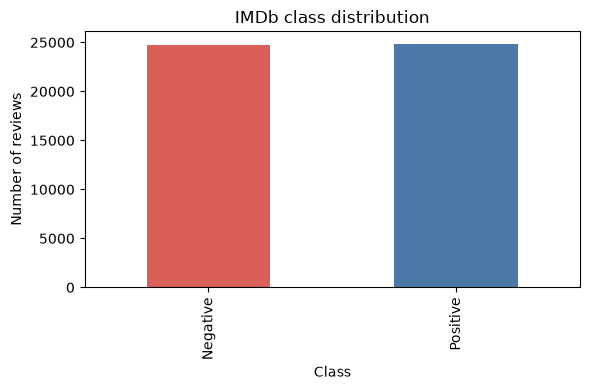

In [4]:
axis = class_distribution.plot.bar(
    x='class', y='count', legend=False, color=['#d95f59', '#4c78a8'], figsize=(6, 4)
)
axis.set_title('IMDb class distribution')
axis.set_xlabel('Class')
axis.set_ylabel('Number of reviews')
plt.tight_layout()
plt.show()

### 11.2. Document length, duplicate và missing values

In [5]:
document_length = dataset['text'].str.split().str.len()
document_length.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).to_frame('word_count').round(2)

,word_count
count,49582.00
mean,231.35
std,171.54
min,4.00
25%,126.00
50%,173.00
75%,281.00
95%,591.00
max,2470.00


In [6]:
quality_report = pd.Series({
    'raw_duplicate_documents': metadata['raw_duplicate_documents'],
    'raw_duplicate_label_conflicts': metadata['raw_duplicate_label_conflicts'],
    'duplicates_after_deduplication': int(dataset['text'].duplicated().sum()),
    'missing_text': int(dataset['text'].isna().sum() + dataset['text'].fillna('').str.strip().eq('').sum()),
    'missing_labels': int(dataset['label'].isna().sum()),
})
quality_report.to_frame('value')

,value
raw_duplicate_documents,418
raw_duplicate_label_conflicts,0
duplicates_after_deduplication,0
missing_text,0
missing_labels,0


### 11.3. Train / Validation / Test split

In [7]:
split_rows = []
for name, frame in splits.items():
    counts = frame['label'].value_counts().sort_index()
    split_rows.append({
        'split': name,
        'samples': len(frame),
        'percentage': round(len(frame) / len(dataset) * 100, 2),
        'negative': int(counts.get(0, 0)),
        'positive': int(counts.get(1, 0)),
    })
split_summary = pd.DataFrame(split_rows)
split_summary

,split,samples,percentage,negative,positive
0,train,29749,60.0,14819,14930
1,validation,9916,20.0,4939,4977
2,test,9917,20.0,4940,4977


**Trả lời:** Dataset không bị imbalance đáng kể vì hai class gần bằng nhau. Sau khi loại 418 document trùng, dataset còn 49.582 samples và không có missing text hoặc missing label.

Dữ liệu được chia stratified thành 60% train, 20% validation và 20% test với `random_state = 42`, nên tỷ lệ positive/negative giữa các tập vẫn gần nhau.

## 12. Data leakage

Nếu fit TF-IDF trên toàn bộ dataset trước khi chia thì vocabulary và IDF đã sử dụng thông tin từ validation/test. Khi đó kết quả đánh giá không còn hoàn toàn độc lập và có thể tốt hơn thực tế.

Trong notebook này, dữ liệu được split trước. TF-IDF và Word2Vec chỉ được fit trên train set, sau đó validation/test chỉ được transform.

## 13. Core implementation

Pipeline chính của bài:

`raw text → representation → Logistic Regression → prediction → evaluation`

TF-IDF hoặc Average Word2Vec tạo vector từ văn bản. Logistic Regression nhận vector này để dự đoán sentiment.

In [8]:
def metric_row(model_name, representation, split_name, y_true, y_pred, train_time, vocab_size):
    return {
        'model': model_name,
        'representation': representation,
        'split': split_name,
        'training_time_sec': round(train_time, 3),
        'vocabulary_size': int(vocab_size),
        'accuracy': round(accuracy_score(y_true, y_pred), 6),
        'precision': round(precision_score(y_true, y_pred), 6),
        'recall': round(recall_score(y_true, y_pred), 6),
        'f1': round(f1_score(y_true, y_pred), 6),
    }


def evaluate_two_splits(model_name, representation, model, X_validation, X_test, train_time, vocab_size):
    validation_pred = model.predict(X_validation)
    test_pred = model.predict(X_test)
    rows = [
        metric_row(model_name, representation, 'validation', validation_df['label'], validation_pred, train_time, vocab_size),
        metric_row(model_name, representation, 'test', test_df['label'], test_pred, train_time, vocab_size),
    ]
    return rows, validation_pred, test_pred

## 14. Experiment 2 — Baseline: TF-IDF + Logistic Regression

In [9]:
baseline_start = perf_counter()
tfidf_unigram = TfidfVectorizer(
    lowercase=True,
    strip_accents='unicode',
    ngram_range=(1, 1),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)
X_train_tfidf = tfidf_unigram.fit_transform(train_df['text'])
X_validation_tfidf = tfidf_unigram.transform(validation_df['text'])
X_test_tfidf = tfidf_unigram.transform(test_df['text'])

lr_tfidf = LogisticRegression(max_iter=1000, solver='liblinear', random_state=RANDOM_STATE)
lr_tfidf.fit(X_train_tfidf, train_df['label'])
baseline_time = perf_counter() - baseline_start

results = []
baseline_rows, baseline_validation_pred, baseline_test_pred = evaluate_two_splits(
    'Logistic Regression',
    'TF-IDF unigram',
    lr_tfidf,
    X_validation_tfidf,
    X_test_tfidf,
    baseline_time,
    len(tfidf_unigram.vocabulary_),
)
results.extend(baseline_rows)
pd.DataFrame(baseline_rows)

,model,representation,split,training_time_sec,vocabulary_size,accuracy,precision,recall,f1
0,Logistic Regression,TF-IDF unigram,validation,7.45,48495,0.895623,0.884211,0.911392,0.897596
1,Logistic Regression,TF-IDF unigram,test,7.45,48495,0.898155,0.890837,0.908379,0.899522


## 15. Experiment 3 — Representation comparison

In [10]:
w2v_start = perf_counter()
train_tokens = [tokenize(text) for text in train_df['text']]
validation_tokens = [tokenize(text) for text in validation_df['text']]
test_tokens = [tokenize(text) for text in test_df['text']]

w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    seed=RANDOM_STATE,
    epochs=5,
)
X_train_w2v = average_word_vectors(train_tokens, w2v_model.wv)
X_validation_w2v = average_word_vectors(validation_tokens, w2v_model.wv)
X_test_w2v = average_word_vectors(test_tokens, w2v_model.wv)

lr_w2v = LogisticRegression(max_iter=1000, solver='liblinear', random_state=RANDOM_STATE)
lr_w2v.fit(X_train_w2v, train_df['label'])
w2v_time = perf_counter() - w2v_start

w2v_rows, w2v_validation_pred, w2v_test_pred = evaluate_two_splits(
    'Logistic Regression',
    'Average Word2Vec',
    lr_w2v,
    X_validation_w2v,
    X_test_w2v,
    w2v_time,
    len(w2v_model.wv),
)
results.extend(w2v_rows)
pd.DataFrame(baseline_rows + w2v_rows)

,model,representation,split,training_time_sec,vocabulary_size,accuracy,precision,recall,f1
0,Logistic Regression,TF-IDF unigram,validation,7.450,48495,0.895623,0.884211,0.911392,0.897596
1,Logistic Regression,TF-IDF unigram,test,7.450,48495,0.898155,0.890837,0.908379,0.899522
2,Logistic Regression,Average Word2Vec,validation,155.271,54102,0.866478,0.859335,0.877637,0.868390
3,Logistic Regression,Average Word2Vec,test,155.271,54102,0.864778,0.860143,0.872413,0.866234


## 16. Vì sao hai representation cho kết quả khác nhau?

Trong lần chạy này, TF-IDF + Logistic Regression có F1 cao hơn Average Word2Vec.

TF-IDF giữ các từ cụ thể có tính phân biệt sentiment như các từ tích cực hoặc tiêu cực. Average Word2Vec có thông tin semantic, nhưng khi lấy trung bình các word vectors thì thứ tự từ bị mất và ảnh hưởng của một số từ sentiment quan trọng có thể bị giảm.

Vì vậy representation khác nhau tạo ra feature khác nhau và dẫn đến kết quả classification khác nhau.

## 17. Experiment 4 — Word order

In [11]:
word_order_examples = pd.DataFrame({
    'text': ['this movie is good', 'this movie is not good']
})
word_order_tfidf = tfidf_unigram.transform(word_order_examples['text'])
word_order_tokens = [tokenize(text) for text in word_order_examples['text']]
word_order_w2v = average_word_vectors(word_order_tokens, w2v_model.wv)

word_order_examples['tfidf_positive_probability'] = lr_tfidf.predict_proba(word_order_tfidf)[:, 1]
word_order_examples['tfidf_prediction'] = lr_tfidf.predict(word_order_tfidf)
word_order_examples['w2v_positive_probability'] = lr_w2v.predict_proba(word_order_w2v)[:, 1]
word_order_examples['w2v_prediction'] = lr_w2v.predict(word_order_w2v)
word_order_examples.round(4)

,text,tfidf_positive_probability,tfidf_prediction,w2v_positive_probability,w2v_prediction
0,this movie is good,0.6824,1,0.9130,1
1,this movie is not good,0.3855,0,0.4736,0


**Trả lời:** Cả hai model đều dự đoán đúng hai câu trong ví dụ này. Tuy nhiên Average Word2Vec không biểu diễn trực tiếp quan hệ phủ định trong cụm `not good`.

Với Average Word2Vec, vector của `not` chỉ được cộng vào rồi lấy trung bình cùng các từ khác. Việc xác suất positive giảm từ 0.9130 xuống 0.4736 cho thấy thêm `not` làm representation thay đổi, nhưng không có nghĩa model hiểu cấu trúc phủ định.

TF-IDF unigram cũng chưa có feature riêng cho `not good`. Bigram có thể biểu diễn cụm này thành một feature riêng.

## 18. Experiment 5 — n-gram features

In [12]:
bigram_start = perf_counter()
tfidf_bigram = TfidfVectorizer(
    lowercase=True,
    strip_accents='unicode',
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True,
)
X_train_bigram = tfidf_bigram.fit_transform(train_df['text'])
X_validation_bigram = tfidf_bigram.transform(validation_df['text'])
X_test_bigram = tfidf_bigram.transform(test_df['text'])

lr_bigram = LogisticRegression(max_iter=1000, solver='liblinear', random_state=RANDOM_STATE)
lr_bigram.fit(X_train_bigram, train_df['label'])
bigram_time = perf_counter() - bigram_start

bigram_rows, bigram_validation_pred, bigram_test_pred = evaluate_two_splits(
    'Logistic Regression',
    'TF-IDF unigram + bigram',
    lr_bigram,
    X_validation_bigram,
    X_test_bigram,
    bigram_time,
    len(tfidf_bigram.vocabulary_),
)
results.extend(bigram_rows)

ngram_comparison = pd.DataFrame(baseline_rows + bigram_rows)
ngram_comparison[['representation', 'split', 'vocabulary_size', 'training_time_sec', 'f1']]

,representation,split,vocabulary_size,training_time_sec,f1
0,TF-IDF unigram,validation,48495,7.450,0.897596
1,TF-IDF unigram,test,48495,7.450,0.899522
2,TF-IDF unigram + bigram,validation,100000,24.169,0.906290
3,TF-IDF unigram + bigram,test,100000,24.169,0.907229


**Trả lời:** Khi thêm bigram, model có thể giữ các cụm như `not good` hoặc `very good` thành feature riêng nên có thêm thông tin hữu ích cho sentiment classification.

Trong lần chạy này, F1 test tăng từ 0.8995 với unigram lên 0.9072 với unigram + bigram. Đổi lại, vocabulary tăng từ 48.495 lên 100.000 features và training time tăng từ 7.45 giây lên 24.17 giây.

## 19. Evaluation

In [13]:
results_df = pd.DataFrame(results)
results_df.to_csv(LAB_DIR / 'results.csv', index=False)
results_df

,model,representation,split,training_time_sec,vocabulary_size,accuracy,precision,recall,f1
0,Logistic Regression,TF-IDF unigram,validation,7.450,48495,0.895623,0.884211,0.911392,0.897596
1,Logistic Regression,TF-IDF unigram,test,7.450,48495,0.898155,0.890837,0.908379,0.899522
2,Logistic Regression,Average Word2Vec,validation,155.271,54102,0.866478,0.859335,0.877637,0.868390
3,Logistic Regression,Average Word2Vec,test,155.271,54102,0.864778,0.860143,0.872413,0.866234
4,Logistic Regression,TF-IDF unigram + bigram,validation,24.169,100000,0.904901,0.896579,0.916215,0.906290
5,Logistic Regression,TF-IDF unigram + bigram,test,24.169,100000,0.905919,0.898031,0.916616,0.907229


**Nhận xét:** Trong ba representation đã thử, TF-IDF unigram + bigram cho kết quả tốt nhất với test F1 = 0.9072. TF-IDF unigram đứng thứ hai với F1 = 0.8995, còn Average Word2Vec có F1 = 0.8662.

Validation và test của cả ba model khá gần nhau. Kết quả cũng cho thấy thêm bigram cải thiện F1 trong thí nghiệm này, nhưng làm vocabulary và thời gian train tăng.

## 20. Confusion matrix

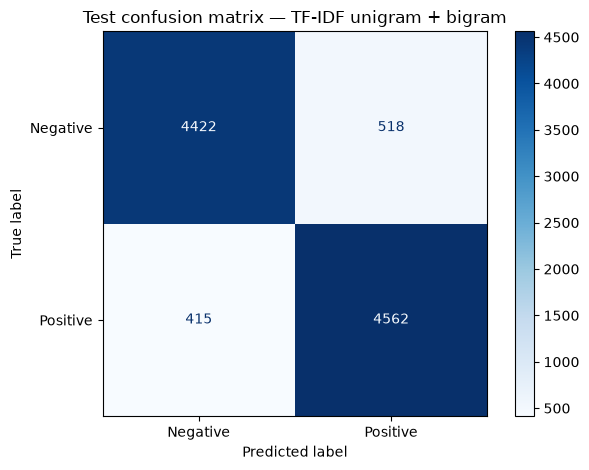

Model được chọn theo validation F1: TF-IDF unigram + bigram
[[4422  518]
 [ 415 4562]]


In [14]:
validation_results = results_df[results_df['split'] == 'validation']
best_representation = validation_results.loc[validation_results['f1'].idxmax(), 'representation']
prediction_by_representation = {
    'TF-IDF unigram': baseline_test_pred,
    'Average Word2Vec': w2v_test_pred,
    'TF-IDF unigram + bigram': bigram_test_pred,
}
best_test_pred = prediction_by_representation[best_representation]
best_confusion_matrix = confusion_matrix(test_df['label'], best_test_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=best_confusion_matrix,
    display_labels=['Negative', 'Positive'],
)
cm_display.plot(cmap='Blues', values_format='d')
cm_display.ax_.set_title(f'Test confusion matrix — {best_representation}')
plt.tight_layout()
plt.savefig(LAB_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

print(f'Model được chọn theo validation F1: {best_representation}')
print(best_confusion_matrix)

**Trả lời:** Model dự đoán sai 518 review negative thành positive và 415 review positive thành negative.

False positive nhiều hơn false negative nên lỗi `negative → positive` xuất hiện nhiều hơn. Điều này cũng phù hợp với việc precision của class positive (0.8980) thấp hơn recall (0.9166).

## 21. Error analysis

In [15]:
error_frame = test_df.copy()
error_frame['prediction'] = best_test_pred
error_frame['correct'] = error_frame['label'] == error_frame['prediction']
error_frame['text_preview'] = error_frame['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 350)

correct_examples = error_frame[error_frame['correct']].groupby('label', group_keys=False).head(2).head(3)
incorrect_examples = error_frame[~error_frame['correct']].groupby('label', group_keys=False).head(2).head(3)
pd.concat([correct_examples, incorrect_examples])[
    ['text_preview', 'label', 'prediction', 'correct']
]

,text_preview,label,prediction,correct
0,Even though I tried to avoid German films rece...,0,0,True
1,Im a big horror fan and I quite enjoyed this r...,1,1,True
2,This is a delightful film. Elizabeth Taylor do...,1,1,True
8,We are not in the fairy tale of the naked empe...,0,1,False
15,Child 'Sexploitation' is one of the most serio...,1,0,False
17,TYSON <br /><br />Aspect ratio: 1.33:1<br /><b...,0,1,False


Chi tiết 3 prediction đúng và 3 prediction sai được trình bày trong `error_analysis.md`.

## 22. Inspect model weights

In [16]:
feature_names = np.asarray(tfidf_unigram.get_feature_names_out())
weights = lr_tfidf.coef_[0]
top_positive = pd.DataFrame({
    'feature': feature_names[np.argsort(weights)[-15:][::-1]],
    'weight': np.sort(weights)[-15:][::-1],
})
top_negative = pd.DataFrame({
    'feature': feature_names[np.argsort(weights)[:15]],
    'weight': np.sort(weights)[:15],
})

print('Top positive features')
display(top_positive.round(4))
print('Top negative features')
display(top_negative.round(4))

Top positive features


,feature,weight
0,great,7.9663
1,excellent,6.3940
2,best,5.6337
3,perfect,5.0616
4,amazing,4.6603
5,wonderful,4.5036
6,loved,4.4813
7,fun,4.1884
8,enjoyed,4.1040
9,well,3.9708


Top negative features


,feature,weight
0,worst,-9.5720
1,bad,-8.2730
2,awful,-7.0546
3,waste,-6.7418
4,boring,-6.3967
5,terrible,-5.9819
6,poor,-5.6643
7,nothing,-5.1963
8,worse,-4.9185
9,horrible,-4.9161


**Trả lời:** Các feature có trọng số positive lớn như `great`, `excellent`, `best`, `perfect`, `amazing` và `wonderful` đều phù hợp với sentiment positive.

Các feature có trọng số negative lớn như `worst`, `bad`, `awful`, `waste`, `boring` và `terrible` cũng phù hợp với sentiment negative.

Có một số feature như `today` hoặc `minutes` không thể hiện sentiment rõ ràng. Điều này cho thấy Logistic Regression học pattern từ corpus IMDb chứ không phải mọi feature có trọng số lớn đều mang ý nghĩa sentiment trực tiếp.

## 23. Application — Sentiment classification

Bài toán ứng dụng là phân loại review phim IMDb thành `positive` hoặc `negative`.

Model được chọn dựa trên validation F1 là TF-IDF unigram + bigram + Logistic Regression. Khi thử với hai review mới, model dự đoán câu có các từ `moving`, `beautifully acted`, `worth watching again` là Positive và câu có `dull`, `painfully bad` là Negative.

In [17]:
custom_reviews = pd.Series([
    'The film was moving, beautifully acted, and worth watching again.',
    'The story was dull and the performances were painfully bad.',
])

if best_representation == 'TF-IDF unigram + bigram':
    custom_features = tfidf_bigram.transform(custom_reviews)
    custom_predictions = lr_bigram.predict(custom_features)
elif best_representation == 'TF-IDF unigram':
    custom_features = tfidf_unigram.transform(custom_reviews)
    custom_predictions = lr_tfidf.predict(custom_features)
else:
    custom_tokens = [tokenize(text) for text in custom_reviews]
    custom_features = average_word_vectors(custom_tokens, w2v_model.wv)
    custom_predictions = lr_w2v.predict(custom_features)

pd.DataFrame({
    'text': custom_reviews,
    'prediction': [label_names[label] for label in custom_predictions],
})

,text,prediction
0,"The film was moving, beautifully acted, and wo...",Positive
1,The story was dull and the performances were p...,Negative
